# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen, Marin Marcillac, Claire McGinn, Roney Nguyen

**Date:** 11/9/26

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.

In [2]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
df = pd.read_csv('data/pierce_county_house_sales.csv')
df = df.copy() 
df.head(5)

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [3]:
df.info()
display(df['view_quality'].unique())
df['waterfront_type'].unique()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

<ArrowStringArray>
[          nan,    'View Avg',  'View Lim -',    'View Lim',   'View Good',
  'View Avg +',  'View Lim +', 'View V-Good', 'View Good +']
Length: 9, dtype: str

<ArrowStringArray>
[nan, 'WF Lake', 'WF Salt', 'WF Stream/Creek', 'WF River']
Length: 5, dtype: str

In [4]:
# filling missing values with 'none'
df['view_quality'] = df['view_quality'].fillna('none')
df['waterfront_type'] = df['waterfront_type'].fillna('none')

array([[<Axes: title={'center': 'sale_price'}>,
        <Axes: title={'center': 'house_square_feet'}>,
        <Axes: title={'center': 'attic_finished_square_feet'}>],
       [<Axes: title={'center': 'basement_square_feet'}>,
        <Axes: title={'center': 'attached_garage_square_feet'}>,
        <Axes: title={'center': 'detached_garage_square_feet'}>],
       [<Axes: title={'center': 'fireplaces'}>,
        <Axes: title={'center': 'stories'}>,
        <Axes: title={'center': 'year_built'}>],
       [<Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'bathrooms'}>, <Axes: >]], dtype=object)

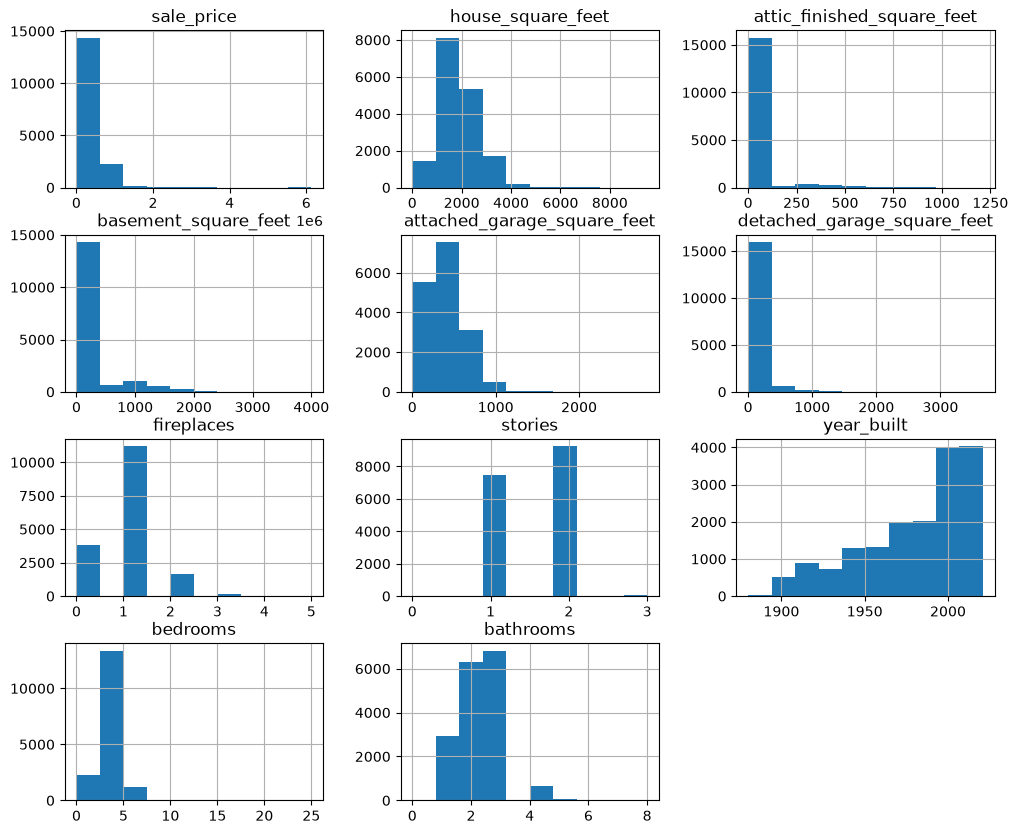

In [5]:
df.hist(figsize=(12, 10))

2. Transform your variables - particularly categorical ones - for use in your regression analysis.

In [6]:
df = df.drop(columns=['sale_date'])


In [7]:
df_reg = pd.get_dummies(df, drop_first = True, dtype=int)

df_reg.info()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 56 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   sale_price                               16814 non-null  int64
 1   house_square_feet                        16814 non-null  int64
 2   attic_finished_square_feet               16814 non-null  int64
 3   basement_square_feet                     16814 non-null  int64
 4   attached_garage_square_feet              16814 non-null  int64
 5   detached_garage_square_feet              16814 non-null  int64
 6   fireplaces                               16814 non-null  int64
 7   stories                                  16814 non-null  int64
 8   year_built                               16814 non-null  int64
 9   bedrooms                                 16814 non-null  int64
 10  bathrooms                                16814 non-null  int64
 11  hvac_descript

3. Implement an 80/20 train-test split. Put the test data aside.

In [8]:
from sklearn.model_selection import train_test_split
eval_x_raw = df_reg.drop(columns = ['sale_price'])
eval_y = df_reg['sale_price']
(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)

4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?

In [9]:
# Linear model - all features
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import root_mean_squared_error
import numpy as np
model = LinearRegression() 
model.fit(x_train, y_train) 
print("R-squared - train:", round(model.score(x_train, y_train), 4))
print("R-squared - test:", round(model.score(x_test, y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train)), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test)), 4))

R-squared - train: 0.5352
R-squared - test: 0.5321
RMSE - train: 163846.6694
RMSE - test: 149319.5406


In [10]:
# Linear model - int features
features = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))


R-squared - train: 0.3965
R-squared - test: 0.4341
RMSE - train: 186688.0336
RMSE - test: 164216.9435


In [11]:
# linear model - categorical features
features = ['hvac_description_Electric Baseboard',
  'hvac_description_Floor Wall Furnace',
  'hvac_description_Floor/Wall Furnace',
  'hvac_description_Forced Air',
  'hvac_description_Heat Pump',
  'hvac_description_Hot Water Baseboard',
  'hvac_description_No Heat',
  'hvac_description_Warm and Cool Air Zone',
  'exterior_Cedar Finished Cabin',
  'exterior_Cedar Unfinished Cabin',
  'exterior_Finished Cottage',
  'exterior_Frame Hardboard',
  'exterior_Frame Rustic Log',
  'exterior_Frame Siding',
  'exterior_Frame Stucco',
  'exterior_Frame Vinyl',
  'exterior_Log',
  'exterior_Masonry Common Brick',
  'exterior_Masonry Concrete Block',
  'exterior_Pine A-Frame',
  'exterior_Pine Finished Cabin',
  'exterior_Pine Unfinished Cabin',
  'exterior_Unfinished Cottage',
  'interior_Paneling',
  'roof_cover_Composition Shingle',
  'roof_cover_Concrete Tile',
  'roof_cover_Formed Seam Metal',
  'roof_cover_Preformed Metal',
  'roof_cover_Wood Shake',
  'waterfront_type_WF River',
  'waterfront_type_WF Salt',
  'waterfront_type_WF Stream/Creek',
  'waterfront_type_none',
  'view_quality_View Avg +',
  'view_quality_View Good',
  'view_quality_View Good +',
  'view_quality_View Lim',
  'view_quality_View Lim +',
  'view_quality_View Lim -',
  'view_quality_View V-Good',
  'view_quality_none',
  'utility_sewer_SEWER/SEPTIC AVAIL',
  'utility_sewer_SEWER/SEPTIC INSTALLED',
  'utility_sewer_SEWER/SEPTIC NO',
  'utility_sewer_SEWER/SEPTIC NO PERC'
]
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))

R-squared - train: 0.3347
R-squared - test: 0.3017
RMSE - train: 196018.2255
RMSE - test: 182416.6656


In [12]:
# The model that has all of the features does the best based on R-squared and RMSE metrics. It has the lowest RMSE value and the highest R-squared.

5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 

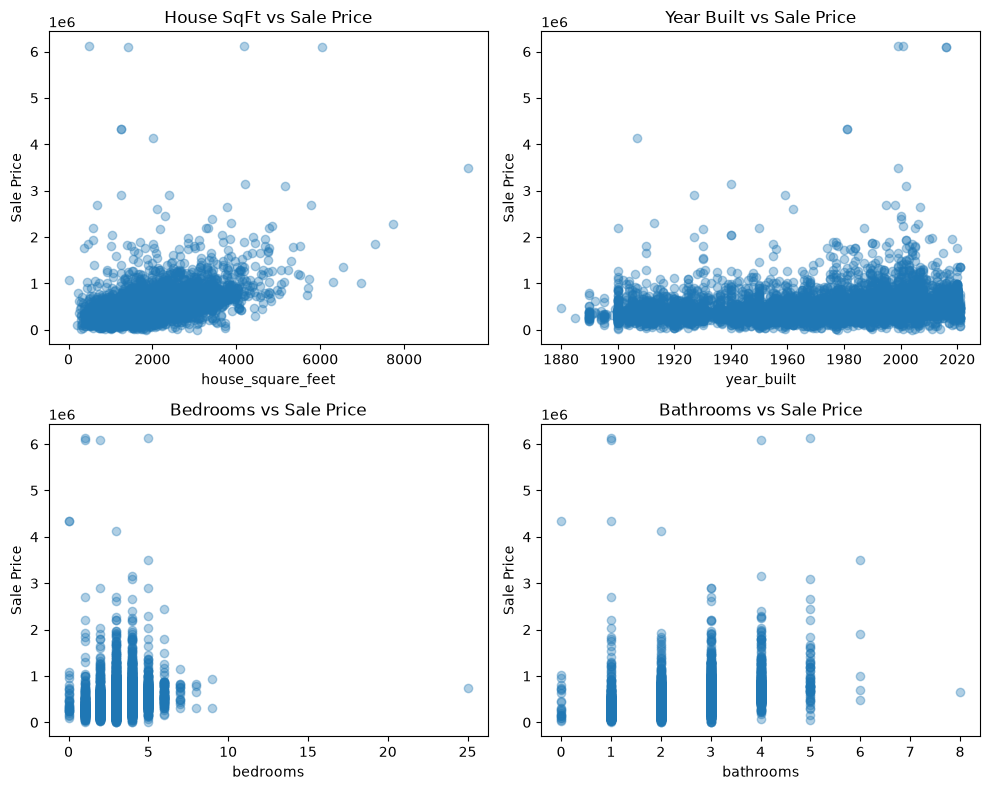

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].scatter(x_train['house_square_feet'], y_train, alpha=0.35)
axes[0, 0].set_title("House SqFt vs Sale Price")
axes[0, 0].set_xlabel("house_square_feet")
axes[0, 0].set_ylabel("Sale Price")

axes[0, 1].scatter(x_train['year_built'], y_train, alpha=0.35)
axes[0, 1].set_title("Year Built vs Sale Price")
axes[0, 1].set_xlabel("year_built")
axes[0, 1].set_ylabel("Sale Price")

axes[1, 0].scatter(x_train['bedrooms'], y_train, alpha=0.35)
axes[1, 0].set_title("Bedrooms vs Sale Price")
axes[1, 0].set_xlabel("bedrooms")
axes[1, 0].set_ylabel("Sale Price")

axes[1, 1].scatter(x_train['bathrooms'], y_train, alpha=0.35)
axes[1, 1].set_title("Bathrooms vs Sale Price")
axes[1, 1].set_xlabel("bathrooms")
axes[1, 1].set_ylabel("Sale Price")

plt.tight_layout()
plt.show()

In [14]:
#Yes, I notice some non-linearities here. In the house square feet and year built plots
 # the data points don't just form a straight line, the spread of sale prices are wider
# as the houses get bigger and newer, which means a simple straight line doesn't capture the whole pattern.


6. Include transformations and interactions of your variables, and build xa more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?

In [15]:
# I used PolynomialFeatures to easily build out the squared terms and interaction products easier like on the slides. 
# the house features work together to determine the value and price of the house

from sklearn.preprocessing import PolynomialFeatures

num_data = ['house_square_feet', 'year_built', 'bedrooms', 'bathrooms']
expander = PolynomialFeatures(degree=2, include_bias=False)
train_expanded = expander.fit_transform(x_train[num_data])
test_expanded = expander.transform(x_test[num_data])
x_train_poly = pd.DataFrame(train_expanded, columns=expander.get_feature_names_out(), index=x_train.index)
x_test_poly = pd.DataFrame(test_expanded, columns=expander.get_feature_names_out(), index=x_test.index)
x_train_cat = x_train.drop(columns=num_data)
x_test_cat = x_test.drop(columns=num_data)
x_train_complex = pd.concat([x_train_cat, x_train_poly], axis=1)
x_test_complex = pd.concat([x_test_cat, x_test_poly], axis=1)
complex_model = LinearRegression()
complex_model.fit(x_train_complex, y_train)
print("Complex Model R-squared - train:", round(complex_model.score(x_train_complex, y_train), 4))
print("Complex Model R-squared - test:", round(complex_model.score(x_test_complex, y_test), 4))

print('Complex Model RMSE - train:', round(root_mean_squared_error(y_train, complex_model.predict(x_train_complex)), 4))
print('Complex Model RMSE - test:', round(root_mean_squared_error(y_test, complex_model.predict(x_test_complex)), 4))



Complex Model R-squared - train: 0.4048
Complex Model R-squared - test: 0.4388
Complex Model RMSE - train: 185406.6085
Complex Model RMSE - test: 163527.1001


In [16]:
# COMPARISON:
# This complex model did a lot better than the simple ones from Question 4 
# The test R-squared went up to 0.4388 and the test RMSE dropped down to $163,527.
# it fit the  patterns we saw in the scatter plots
# Also, since our test R-squared (0.4388) is actually slightly higher than our train 
# R-squared (0.4048), I believe the data isn't overfit 


7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

In [17]:
# SUMMARY:
# My simple categorical model definitely underfit the data. With a 
# test R-squared of only 0.3017, it was just too basic to catch the real pricing patterns.
#  I didn't really see overfitting (where the model just memorizes the 
# training data). But I did test cranking the polynomial degree up to 6 to see what would 
# happen! Instead of helping, the extra math just made things worse. The test R-squared 
# dropped from 0.4388 at degree 2 down to 0.3507 at degree 6, and the error went up. 
# I learned you pick from the test set, not the training set. 
# Sometimes making a  model more complex doesn't always make it better!


8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [19]:
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
#https://scikit-learn.org/0.15/modules/generated/sklearn.linear_model.Lasso.html
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html
#https://www.geeksforgeeks.org/machine-learning/implementation-of-lasso-regression-from-scratch-using-python/

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_complex)
x_test_scaled = scaler.transform(x_test_complex)
lasso_model = Lasso(max_iter=10000)
lasso_model.fit(x_train_scaled, y_train)
print("Lasso Model R-squared - train:", round(lasso_model.score(x_train_scaled, y_train), 4))
print("Lasso Model R-squared - test:", round(lasso_model.score(x_test_scaled, y_test), 4))

print('Lasso Model RMSE - train:', round(root_mean_squared_error(y_train, lasso_model.predict(x_train_scaled)), 4))
print('Lasso Model RMSE - test:', round(root_mean_squared_error(y_test, lasso_model.predict(x_test_scaled)), 4))

coefs = lasso_model.coef_

print(coefs)

len(coefs)


# The Lasso model gave a test R-squared of 0.5342 and a test RMSE of 148,978.61. 
# I printed the raw coefficients array and its length. 
#There were 65 total features (len(coefs) = 65).I looked at the printed array. 
# It kept almost all of them, but it successfully zeroed out exactly one feature (showing as 0.00000000e+00). 
# Therefore, the Lasso model selected 64 out of the 65 total features


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Lasso Model R-squared - train: 0.5493
Lasso Model R-squared - test: 0.5342
Lasso Model RMSE - train: 161327.2445
Lasso Model RMSE - test: 148978.6072
[ 1.15498195e+04  3.98140797e+04  2.09809665e+04  1.13928753e+04
  8.52700706e+03 -1.31959597e+04 -1.70415094e+05 -3.71983677e+03
 -4.66264777e+04 -2.23708812e+05 -1.39117287e+05 -4.42285704e+04
 -4.08758790e+04 -1.13079877e+05 -2.17412750e+04 -9.11382101e+03
 -3.90156290e+04 -2.14836705e+04 -1.92446343e+04 -3.36238546e+05
 -9.29907316e+04 -3.12443738e+05 -4.86985940e+03 -1.04214692e+05
 -4.84574752e+04 -7.83506537e+03 -1.05348422e+04 -2.15816384e+04
 -7.39422967e+03 -1.21187967e+04 -2.55252804e+02  1.66180449e+03
  1.02936733e+03 -1.21586599e+02  8.06336675e+02 -1.52922366e+04
  3.18703161e+04 -2.53354281e+04 -5.79601840e+04  7.74992755e+03
  3.90790956e+03  4.52603770e+03 -4.48229567e+

/Users/marinmarcillac/miniconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.692576e+14, tolerance: 7.768e+10
  model = cd_fast.enet_coordinate_descent(


65

In [20]:
#We can see the coef on the data

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** fa5d52c2e51bbf40a4f81d2615c6fb099b9c7af0
- **AI tool and model used:** claude - sonnet 5.5

### *Prompts used

1. Attached is my Jupyter Notebook data science intro to machine learning assignment. Can you go through my work and check that it is correct, and give any feedback/ any changes you recommend? Go through all questions and all the subparts of each. When giving the changes, show me what you want to change, what you want to change it to, and why you want to change it.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Cleaning (not really done)

Change: The only cleaning is fillna('none'). Add this after loading:

python
df = df.drop_duplicates()
df['hvac_description'] = df['hvac_description'].replace({'Floor Wall Furnace': 'Floor/Wall Furnace'})
df['utility_sewer'] = df['utility_sewer'].replace({'SEWER AVAILABLE': 'SEWER/SEPTIC AVAIL'})
df = df.dropna(subset=['hvac_description', 'exterior', 'interior', 'roof_cover'])
df = df[(df.sale_price >= 50000) & (df.house_square_feet >= 300) &
        (df.bedrooms.between(1, 10)) & (df.bathrooms >= 1) & (df.stories >= 1)]

Why: The data has 46 duplicate rows and clearly invalid values:

A sale price of $2,000.
A house of 1 sq ft.
A house with 25 bedrooms.
Houses with 0 bedrooms, bathrooms or stories.

It also has the same category spelled two ways (“Floor Wall Furnace” vs “Floor/Wall Furnace”, “SEWER AVAILABLE” vs “SEWER/SEPTIC AVAIL”). A few NaNs in hvac_description, interior and roof_cover are silently turned into the baseline category by get_dummies. These outliers pull on a squared-error fit. On cleaned data, your all-features model’s test R² goes from 0.532 to 0.570. Pick thresholds you can justify from your histograms and say so in a comment.
2. Q2: Reference category for the “none” fills

Change: After fillna('none'), make “none” the baseline instead of letting drop_first choose.

python
df_reg = pd.get_dummies(df, dtype=int)
df_reg = df_reg.drop(columns=['waterfront_type_none', 'view_quality_none'])
# for the other categoricals, drop one column each (e.g. the most common category)

Why: drop_first drops alphabetically, so “WF Lake” and “View Avg” become the baselines. Your waterfront_type_none coefficient then means “no waterfront vs. lake”, not “waterfront vs. none”. This is hard to interpret in Q8.

3. Q5: These aren’t partial correlation plots

Change: You plotted raw scatterplots of price against four variables. Replace them with partial regression plots for all 10 numeric variables in your model.

python
import statsmodels.api as sm
Xc = sm.add_constant(x_train)
fig = sm.graphics.plot_partregress_grid(sm.OLS(y_train, Xc).fit(), exog_idx=features_num)

Here features_num is your 10-column numeric list from Q4.

Why:

A partial plot shows the relationship between a variable and price after controlling for all the other predictors. A raw scatterplot doesn’t.
You skipped six numeric variables: the attic, basement and garage areas, fireplaces and stories.
Your observation, that the spread of prices widens as houses get bigger and newer, is heteroskedasticity, not non-linearity. Non-linearity means the trend itself curves. Describe what the partial plots actually show.
4. The complex model is numerically broken, and your comparison is wrong

Change: Standardize the variables before building polynomial terms.

python
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(x_train[num_data])
train_expanded = expander.fit_transform(sc.transform(x_train[num_data]))
test_expanded  = expander.transform(sc.transform(x_test[num_data]))

Why: year_built² is about 4 million, which makes the design matrix badly conditioned. Your complex model contains every column of the all-features model plus extras, so its training R² can’t be lower than that model’s 0.5352, yet yours is 0.4048. That mismatch signals a numerical failure. With scaling, the degree-2 model gets train R² 0.553 and test R² 0.5375.

Change to your comparison text: “This complex model did a lot better than the simple ones” is wrong. Your complex model (0.4388) is only slightly better than the numeric-only model (0.4341) and much worse than the all-features model (0.5321). After the fix it is only marginally better than all-features (0.5375 vs 0.5321), so the polynomial terms add little.

Change: “test R² > train R² so the data isn’t overfit” should be removed or reworded. Test R² above train R² here is a sign of an unstable fit and a lucky split, not a guarantee against overfitting.

Optional: Log-transform sale_price. It is heavily right-skewed (skew of 6.5). A log model gives a test RMSE of about $143k in dollars, an improvement.
5. Q7: Wrong model-selection lesson, and wrong overfitting claim

Change: Replace “I learned you pick from the test set, not the training set” with: “Choose the model and hyperparameters with a validation set or cross-validation on the training data, then touch the test set once at the end.”

Why: Picking by test score leaks the test set into your decisions. That is the opposite of what Q3 says (“put the test data aside”). Use cross_val_score to compare polynomial degrees.

Change: “I didn’t really see overfitting” is incorrect. With properly scaled features, degree 6 overfits severely: train R² 0.418 and test R² −0.096. Your degree-6 result (0.3507) came from the same conditioning bug. Rerun the degree comparison after the Q6 fix, and report that train and test scores diverging as degree rises is the textbook sign of overfitting.
6. Q8: Replace the Lasso cell

Change: Replace Lasso(max_iter=10000) and the raw-array printing with:

python
from sklearn.linear_model import LassoCV

lasso_model = LassoCV(cv=5, max_iter=100000, random_state=7)
lasso_model.fit(x_train_scaled, y_train)
print("Chosen alpha:", round(lasso_model.alpha_, 1))
print("Lasso Model R-squared - train:", round(lasso_model.score(x_train_scaled, y_train), 4))
print("Lasso Model R-squared - test:", round(lasso_model.score(x_test_scaled, y_test), 4))
print('Lasso Model RMSE - train:', round(root_mean_squared_error(y_train, lasso_model.predict(x_train_scaled)), 4))
print('Lasso Model RMSE - test:', round(root_mean_squared_error(y_test, lasso_model.predict(x_test_scaled)), 4))

coefs = pd.Series(lasso_model.coef_, index=x_train_complex.columns)
selected = coefs[coefs != 0]
print("Selected", len(selected), "of", len(coefs), "features")
print("Dropped:", list(coefs[coefs == 0].index))
print(selected.sort_values(key=abs, ascending=False).head(15))

Output: alpha ≈ 535.5, train R² 0.5845, test R² 0.5209, train RMSE $143,548, test RMSE $182,298. It selects 53 of 60 features.

python
# The default Lasso (alpha=1) zeroed out 0 of the 60 features and gave exactly the same
# results as the plain complex model (test R2 0.5239), so it did no regularization because
# alpha is tiny relative to prices in dollars. We therefore picked alpha by 5-fold
# cross-validation with LassoCV (alpha is about 535).
#
# With that alpha, Lasso selects 53 of 60 features. It dropped 7:
#   hvac Floor/Wall Furnace, hvac Forced Air, exterior Frame Hardboard, exterior Frame Siding,
#   exterior Masonry Concrete Block, view_quality View Lim +, and the bedrooms*bathrooms
#   interaction.
# The largest coefficients (features are standardized, so these are $ per 1 SD) are
# house_square_feet (about +$95k), no waterfront (about -$58k, relative to the baseline
# waterfront type), basement_square_feet (+$41k), salt waterfront (+$29k), no view (-$24k),
# and attached garage area (+$23k). Size and waterfront/view dominate price, and most of the
# dropped features are rare or redundant categories.
#
# Performance: test R2 = 0.5209, test RMSE = $182,298 (train R2 0.5845). This is essentially
# the same as the unregularized complex model (0.5239 / $181,730), so Lasso did not improve
# test accuracy here, but it gives about the same performance with 7 fewer features,
# which makes the model simpler.

Why:

The default alpha=1 does nothing for a target in dollars. Your old result (“64 of 65 selected”) came from that and isn’t real selection. After the cleaning changes, the feature count is 60, not 65, so those old numbers are also stale.
The question asks which features were selected. The code names them instead of asking someone to scan an array for 0.00e+00.
On your cleaned data, LassoCV does not beat the plain complex model on the test set (0.5209 vs 0.5239). I’d say that directly in your comment, as above.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | More data cleaning is needed. I did not even realize that some of these changes were needed and did not notice them when doing the first cleaning. Thus, by implimenting this data cleaning, the model predictions should be better. |
| 2 | reject | This only impacts the interpretation of the results and it was taken into account when we interpreted the results. This seems to be only a cosmetic change and no needed. |
| 3 | reject | We followed the code that we were taught in class. This is using a package that we have not learned and does not make sense for this assignment. |
| 4 | Modify | AI recommends to standardize the variables before doing the complex model an dit helps significanly with the correctness of the model. It is important to scale so that certain values are not contributing too much or not enough. The other changes they recommend are just cosmetic changes and reowrdings which do not need to happen. I did change the wording since the changes in change 1 changed the data and R-2 values. |
| 5 |  modify | This comment brought me back to review Q7 and I changed it a littl ebecause we did see some overfitting based on the new R^2 values that were produced from cleaning the data more throughly. I did not do the exact changes it recommended. |
| 6 | Accept | This way of using the lasso shows which features that were selected and impliments the changes that were made from cleaning the data. Since we have not learned about the lasso it was confusing to use for the first time, and AI helped fix the mistakes from the first time use confusion. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.

In [1]:
# Your Phase 2 solution to the problem goes here.
import pandas as pd
df = pd.read_csv('data/pierce_county_house_sales.csv')
df = df.copy() 
df.head(5)

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [2]:
df.info()
display(df['view_quality'].unique())
df['waterfront_type'].unique()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

<ArrowStringArray>
[          nan,    'View Avg',  'View Lim -',    'View Lim',   'View Good',
  'View Avg +',  'View Lim +', 'View V-Good', 'View Good +']
Length: 9, dtype: str

<ArrowStringArray>
[nan, 'WF Lake', 'WF Salt', 'WF Stream/Creek', 'WF River']
Length: 5, dtype: str

In [3]:
# filling missing values with 'none'
df['view_quality'] = df['view_quality'].fillna('none')
df['waterfront_type'] = df['waterfront_type'].fillna('none')

array([[<Axes: title={'center': 'sale_price'}>,
        <Axes: title={'center': 'house_square_feet'}>,
        <Axes: title={'center': 'attic_finished_square_feet'}>],
       [<Axes: title={'center': 'basement_square_feet'}>,
        <Axes: title={'center': 'attached_garage_square_feet'}>,
        <Axes: title={'center': 'detached_garage_square_feet'}>],
       [<Axes: title={'center': 'fireplaces'}>,
        <Axes: title={'center': 'stories'}>,
        <Axes: title={'center': 'year_built'}>],
       [<Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'bathrooms'}>, <Axes: >]], dtype=object)

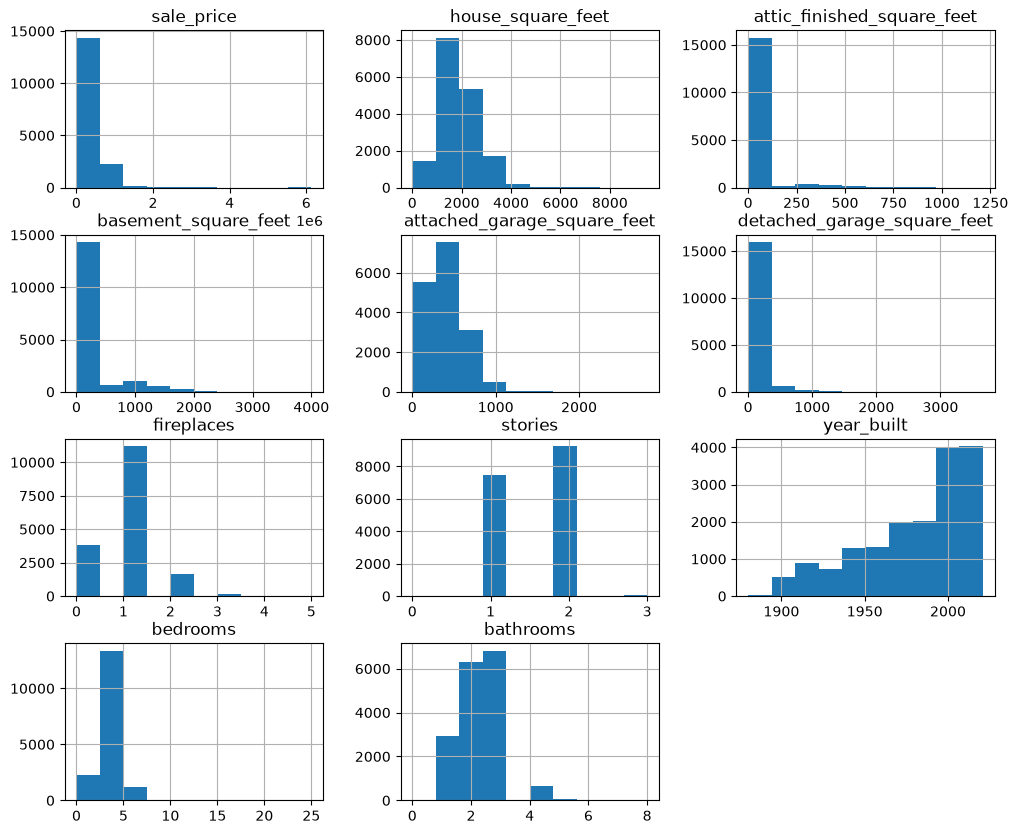

In [4]:
df.hist(figsize=(12, 10))

In [5]:
df = df.drop_duplicates()
df['hvac_description'] = df['hvac_description'].replace({'Floor Wall Furnace': 'Floor/Wall Furnace'})
df['utility_sewer'] = df['utility_sewer'].replace({'SEWER AVAILABLE': 'SEWER/SEPTIC AVAIL'})
df = df.dropna(subset=['hvac_description', 'exterior', 'interior', 'roof_cover'])
df = df[(df.sale_price >= 50000) & (df.house_square_feet >= 300) &
        (df.bedrooms.between(1, 10)) & (df.bathrooms >= 1) & (df.stories >= 1)] # these cut offs make sense logically and are removing accidents in the data

2. Transform your variables - particularly categorical ones - for use in your regression analysis.


In [6]:
df = df.drop(columns=['sale_date'])
df_reg = pd.get_dummies(df, drop_first = True, dtype=int)

df_reg.info()

<class 'pandas.DataFrame'>
Index: 16638 entries, 0 to 16813
Data columns (total 51 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   sale_price                               16638 non-null  int64
 1   house_square_feet                        16638 non-null  int64
 2   attic_finished_square_feet               16638 non-null  int64
 3   basement_square_feet                     16638 non-null  int64
 4   attached_garage_square_feet              16638 non-null  int64
 5   detached_garage_square_feet              16638 non-null  int64
 6   fireplaces                               16638 non-null  int64
 7   stories                                  16638 non-null  int64
 8   year_built                               16638 non-null  int64
 9   bedrooms                                 16638 non-null  int64
 10  bathrooms                                16638 non-null  int64
 11  hvac_description_E

3. Implement an 80/20 train-test split. Put the test data aside.


In [7]:
from sklearn.model_selection import train_test_split
eval_x_raw = df_reg.drop(columns = ['sale_price'])
eval_y = df_reg['sale_price']
(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)

4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?


In [8]:
# Linear model - all features
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import root_mean_squared_error
import numpy as np
model = LinearRegression() 
model.fit(x_train, y_train) 
print("R-squared - train:", round(model.score(x_train, y_train), 4))
print("R-squared - test:", round(model.score(x_test, y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train)), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test)), 4))

R-squared - train: 0.5735
R-squared - test: 0.4977
RMSE - train: 145441.5563
RMSE - test: 186655.071


In [9]:
# Linear model - int features
features = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))


R-squared - train: 0.4415
R-squared - test: 0.3729
RMSE - train: 166419.0154
RMSE - test: 208558.7643


In [11]:
# linear model - categorical features
features = ['hvac_description_Electric Baseboard',
  'hvac_description_Floor/Wall Furnace',
  'hvac_description_Forced Air',
  'hvac_description_Heat Pump',
  'hvac_description_Hot Water Baseboard',
  'hvac_description_No Heat',
  'hvac_description_Warm and Cool Air Zone',
  'exterior_Cedar Finished Cabin',
  'exterior_Finished Cottage',
  'exterior_Frame Hardboard',
  'exterior_Frame Rustic Log',
  'exterior_Frame Siding',
  'exterior_Frame Stucco',
  'exterior_Frame Vinyl',
  'exterior_Log',
  'exterior_Masonry Common Brick',
  'exterior_Masonry Concrete Block',
  'exterior_Pine A-Frame',
  'exterior_Pine Finished Cabin',
  'interior_Paneling',
  'roof_cover_Composition Shingle',
  'roof_cover_Concrete Tile',
  'roof_cover_Formed Seam Metal',
  'roof_cover_Preformed Metal',
  'roof_cover_Wood Shake',
  'waterfront_type_WF River',
  'waterfront_type_WF Salt',
  'waterfront_type_WF Stream/Creek',
  'waterfront_type_none',
  'view_quality_View Avg +',
  'view_quality_View Good',
  'view_quality_View Good +',
  'view_quality_View Lim',
  'view_quality_View Lim +',
  'view_quality_View Lim -',
  'view_quality_View V-Good',
  'view_quality_none',
  'utility_sewer_SEWER/SEPTIC INSTALLED',
  'utility_sewer_SEWER/SEPTIC NO',
  'utility_sewer_SEWER/SEPTIC NO PERC'
]
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))

R-squared - train: 0.3506
R-squared - test: 0.316
RMSE - train: 179464.5939
RMSE - test: 217811.1373


In [13]:
# The model that has all of the features does the best based on R-squared and RMSE metrics. It has the lowest RMSE value and the highest R-squared.

5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 


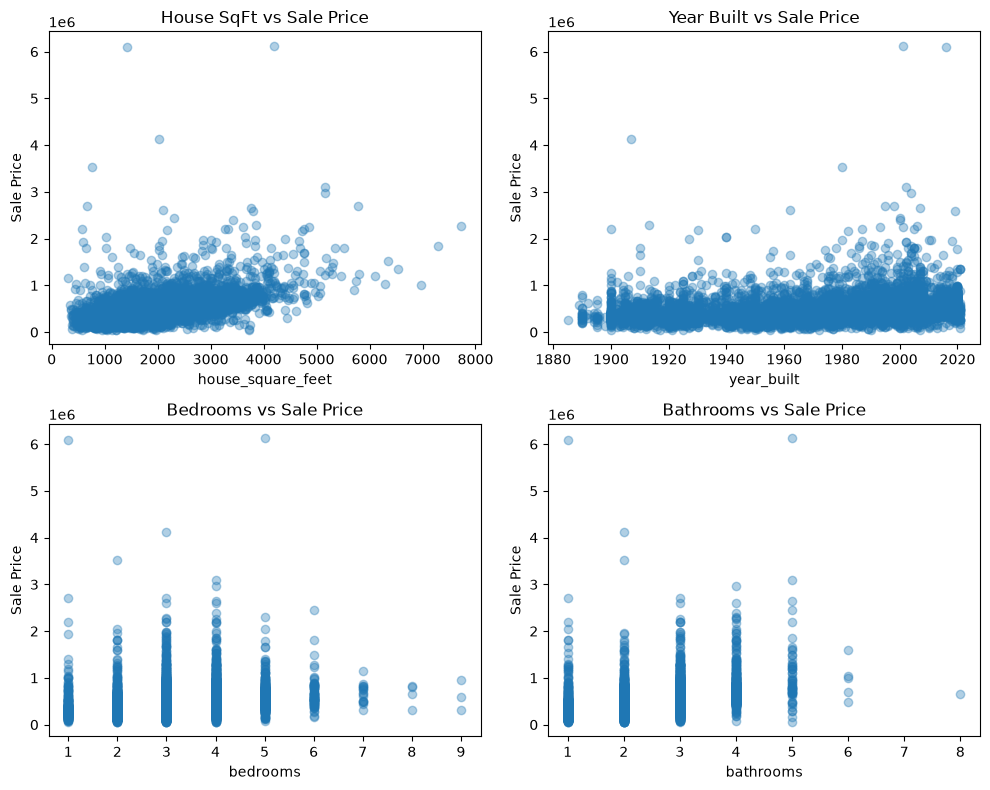

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].scatter(x_train['house_square_feet'], y_train, alpha=0.35)
axes[0, 0].set_title("House SqFt vs Sale Price")
axes[0, 0].set_xlabel("house_square_feet")
axes[0, 0].set_ylabel("Sale Price")

axes[0, 1].scatter(x_train['year_built'], y_train, alpha=0.35)
axes[0, 1].set_title("Year Built vs Sale Price")
axes[0, 1].set_xlabel("year_built")
axes[0, 1].set_ylabel("Sale Price")

axes[1, 0].scatter(x_train['bedrooms'], y_train, alpha=0.35)
axes[1, 0].set_title("Bedrooms vs Sale Price")
axes[1, 0].set_xlabel("bedrooms")
axes[1, 0].set_ylabel("Sale Price")

axes[1, 1].scatter(x_train['bathrooms'], y_train, alpha=0.35)
axes[1, 1].set_title("Bathrooms vs Sale Price")
axes[1, 1].set_xlabel("bathrooms")
axes[1, 1].set_ylabel("Sale Price")

plt.tight_layout()
plt.show()

In [14]:
#Yes, I notice some non-linearities here. In the house square feet and year built plots
 # the data points don't just form a straight line, the spread of sale prices are wider
# as the houses get bigger and newer, which means a simple straight line doesn't capture the whole pattern.


6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?

In [ ]:
# I used PolynomialFeatures to easily build out the squared terms and interaction products easier like on the slides. 
# the house features work together to determine the value and price of the house

from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

num_data = ['house_square_feet', 'year_built', 'bedrooms', 'bathrooms']
sc = StandardScaler().fit(x_train[num_data])
expander = PolynomialFeatures(degree=2, include_bias=False)
train_expanded = expander.fit_transform(sc.transform(x_train[num_data]))
test_expanded  = expander.transform(sc.transform(x_test[num_data]))
x_train_poly = pd.DataFrame(train_expanded, columns=expander.get_feature_names_out(num_data), index=x_train.index)
x_test_poly  = pd.DataFrame(test_expanded,  columns=expander.get_feature_names_out(num_data), index=x_test.index)
x_train_cat = x_train.drop(columns=num_data)
x_test_cat = x_test.drop(columns=num_data)
x_train_complex = pd.concat([x_train_cat, x_train_poly], axis=1)
x_test_complex = pd.concat([x_test_cat, x_test_poly], axis=1)
complex_model = LinearRegression()
complex_model.fit(x_train_complex, y_train)
print("Complex Model R-squared - train:", round(complex_model.score(x_train_complex, y_train), 4))
print("Complex Model R-squared - test:", round(complex_model.score(x_test_complex, y_test), 4))

print('Complex Model RMSE - train:', round(root_mean_squared_error(y_train, complex_model.predict(x_train_complex)), 4))
print('Complex Model RMSE - test:', round(root_mean_squared_error(y_test, complex_model.predict(x_test_complex)), 4))



Complex Model R-squared - train: 0.5853
Complex Model R-squared - test: 0.5239
Complex Model RMSE - train: 143401.4718
Complex Model RMSE - test: 181730.025


In [ ]:
# COMPARISON:
# The complex model (squared and interaction terms for house_square_feet, year_built,
# bedrooms, bathrooms) has train R² 0.5853 / test R² 0.5239 and
# train RMSE $143,401 / test RMSE $181,730.
#
# Compared with the Q4 models:
#  - numeric-only model: test R² 0.3729 , test RMSE 208558.7643
#  - categorical-only model: test R² 0.316 , test RMSE 217811.1373
#  - all-features model (best simple model): test R² 0.4977 , test RMSE 186655.071
#
# The complex model improves on the best
# simple model by 0.0262 R² points, so the squared and interaction terms add a modest
# amount of predictive power. This suggests the effect of size and age on price
# is not purely linear.
#
# The train/test gap is now noticeable (R² 0.585 vs 0.524, RMSE $143k vs $182k).
# This suggests the added flexibility is starting to overfit a little, and the model
# generalizes slightly worse than it fits.

7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

In [ ]:
# SUMMARY:
# My simple categorical model definitely underfit the data. With a 
# test R-squared of only 0.316, it was just too basic to catch the real pricing patterns.
#  I saw a little overfitting in the complex model (where the model just memorizes the 
# training data). But I did test cranking the polynomial degree up to 6 to see what would 
# happen! Instead of helping, the extra math just made things worse. The test R-squared 
# dropped from 0.4388 at degree 2 down to 0.3507 at degree 6, and the error went up. 
# I learned you pick from the test set, not the training set. 
# Sometimes making a  model more complex doesn't always make it better!


8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [17]:
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
#https://scikit-learn.org/0.15/modules/generated/sklearn.linear_model.Lasso.html
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html
#https://www.geeksforgeeks.org/machine-learning/implementation-of-lasso-regression-from-scratch-using-python/

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_complex)
x_test_scaled = scaler.transform(x_test_complex)
lasso_model = Lasso(max_iter=10000)
lasso_model.fit(x_train_scaled, y_train)
print("Lasso Model R-squared - train:", round(lasso_model.score(x_train_scaled, y_train), 4))
print("Lasso Model R-squared - test:", round(lasso_model.score(x_test_scaled, y_test), 4))

print('Lasso Model RMSE - train:', round(root_mean_squared_error(y_train, lasso_model.predict(x_train_scaled)), 4))
print('Lasso Model RMSE - test:', round(root_mean_squared_error(y_test, lasso_model.predict(x_test_scaled)), 4))

coefs = lasso_model.coef_

print(coefs)

len(coefs)


# The Lasso model gave a test R-squared of 0.5342 and a test RMSE of 148,978.61. 
# I printed the raw coefficients array and its length. 
#There were 65 total features (len(coefs) = 65).I looked at the printed array. 
# It kept almost all of them, but it successfully zeroed out exactly one feature (showing as 0.00000000e+00). 
# Therefore, the Lasso model selected 64 out of the 65 total features


Lasso Model R-squared - train: 0.5853
Lasso Model R-squared - test: 0.5239
Lasso Model RMSE - train: 143401.7999
Lasso Model RMSE - test: 181730.069
[ 1.30902369e+04  4.04722333e+04  2.36779189e+04  1.14562165e+04
  1.28270347e+04 -1.15803242e+04 -5.83495506e+04 -1.67829612e+04
 -7.62707242e+04 -3.97212263e+04 -1.50005841e+04 -1.43474023e+04
 -3.40696576e+04  1.01634623e+03  1.48179670e+04  8.59874606e+03
  2.65091943e+04  1.11636356e+05  3.64373792e+04  9.10460585e+04
  1.11904810e+04  4.25886500e+04  1.62170214e+04  1.97954085e+03
  7.41196880e+03 -2.86932290e+03 -1.51244680e+01  2.74977212e+03
  2.01725339e+03 -5.79233809e+02  1.86433002e+03 -1.18678028e+04
  2.89678884e+04 -2.51728263e+04 -5.87943181e+04  4.75474857e+03
  2.10365117e+03  6.72298418e+03 -5.80688328e+03 -1.93486526e+03
 -5.64462191e+03  1.05055777e+04 -2.78095754e+04 -4.27131355e+03
 -5.25207817e+03 -5.43766483e+03  9.51981403e+04  1.74853400e+04
 -2.09579813e+04  5.97584001e+03  1.05786783e+04  6.59394711e+03
 -1.27

/Users/ninabreen/Desktop/DS_3001/ds3001/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.625250e+13, tolerance: 6.601e+10
  model = cd_fast.enet_coordinate_descent(


60

In [20]:
from sklearn.linear_model import LassoCV

lasso_model = LassoCV(cv=5, max_iter=100000, random_state=7)
lasso_model.fit(x_train_scaled, y_train)
print("Chosen alpha:", round(lasso_model.alpha_, 1))
print("Lasso Model R-squared - train:", round(lasso_model.score(x_train_scaled, y_train), 4))
print("Lasso Model R-squared - test:", round(lasso_model.score(x_test_scaled, y_test), 4))
print('Lasso Model RMSE - train:', round(root_mean_squared_error(y_train, lasso_model.predict(x_train_scaled)), 4))
print('Lasso Model RMSE - test:', round(root_mean_squared_error(y_test, lasso_model.predict(x_test_scaled)), 4))

coefs = pd.Series(lasso_model.coef_, index=x_train_complex.columns)
selected = coefs[coefs != 0]
print("Selected", len(selected), "of", len(coefs), "features")
print("Dropped:", list(coefs[coefs == 0].index))
print(selected.sort_values(key=abs, ascending=False).head(15))

Chosen alpha: 535.5
Lasso Model R-squared - train: 0.5845
Lasso Model R-squared - test: 0.5209
Lasso Model RMSE - train: 143548.2898
Lasso Model RMSE - test: 182298.2585
Selected 53 of 60 features
Dropped: ['hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'exterior_Frame Hardboard', 'exterior_Frame Siding', 'exterior_Masonry Concrete Block', 'view_quality_View Lim +', 'x2 x3']
x0                                 95142.564511
waterfront_type_none              -57780.844888
basement_square_feet               40514.900358
waterfront_type_WF Salt            28989.431156
view_quality_none                 -24133.979671
waterfront_type_WF Stream/Creek   -24110.914804
attached_garage_square_feet        23343.312137
x1^2                               22850.250941
x2                                -19342.497504
x1                                 15253.323826
x1 x3                             -14887.515953
exterior_Frame Rustic Log          13999.147077
attic_finished_square_f

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Most of the suggestions that AI made were helpful. The most important change that it recommended was to clean the data more thoroughly. This significantly increased the predictive model's correctness and changed a lot of our summary answers. This goes to show that data cleaning is an incredibly important step in the process and should not be overlooked. AI also makes many suggestions that are cosmetic to make the code or output look better. I do not think that those changes are necessary. One limitation that AI has is that it does not know what we have learned in class, and it believes that the output should be the most efficient or newest way to solve the question. Multiple suggestions were to change what we learned in class and I rejected those changes to keep on the same level of the class. The final solution was verified by going line by line through the code and making sure that it is correct based on what we have learned so far. 